# `demo_crit_db`: synthetic AR(12) data, distance to $M_6$

> **NOT OWN WORK.** Python port of `demo/demo_crit_db.m` from the MATLAB *prox_crit_toolkit* by J. S. Sooter et al.
> ([GitHub](https://github.com/sam-sooter/prox_crit_toolkit), fetched 2026-10-09; CC BY-NC 4.0),
> translated by Andre Potthoff (with Claude). Text and code follow the original cell by cell; additions are marked *[port note]*.
> Functions: `src/analysis/prox_crit/` (see `NOTICE.md`, `FLAGS.md`).

*[port note]* Flags for this script (FLAG 11 in `FLAGS.md`):
- The original comment says "calculate d2", but the script sets `b = 6`, so it computes $d_6$.
- It sets `with_err_bars = true` together with `fit_method = 'YuleWalker'`. That combination always ends in the "error bar calculation not supported" path, which returns `sddb = NaN` and `exit_status = 1`. This is kept as is, so a warning is expected below.
- The original's `if (0)` block (the tutorial's AR(3) example) is dead code and is omitted here.

FLAG 15 also applies: for b ≥ 4, MATLAB's `fmincon` stops early, so the Python $d_6$ can be lower than MATLAB's.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio

from src.analysis.prox_crit import calc_db, run_ar, get_spike_counts, matlab_colon
from src.config.paths import YMV15_MAT, FIGURES_DIR, RESULTS_OBJECTS
from src.analysis.prox_crit.manifold import _ar_roots  # roots of 1 - sum kern_k z^k

### Generating synthetic data

In [2]:
n = 12; p = 0.7
if n > 6:
    kern = (-p) ** np.arange(n); sigma = 1  # AR model parameters
else:
    kern = p ** np.arange(n); sigma = 1
kern = 0.95 * kern / kern.sum()

# However I make the kernel, it's possible I come up with an explosive one.
# Scale down the kernel until I get something ok.
minroot = np.min(np.abs(_ar_roots(kern)))  # MATLAB: min(abs(roots([fliplr(kern(:)') -1])))
while minroot < 1:
    kern = kern * minroot * 0.99
    minroot = np.min(np.abs(_ar_roots(kern)))
    print("Adjusting kernel for stability")

T = int(1e4)  # number of time steps
x = run_ar(kern, sigma, T, rng=np.random.default_rng(0))  # simulate AR model

In [3]:
# d_b settings (MINIMAL)
order = len(kern)  # AR model order
delta_t = 1  # time between consecutive steps in time series (in s)
b = 6  # (original comment: "calculate d2 (rather than d4, d6, ...)", but b = 6, FLAG 11)

# Optional arguments
dbopt = dict(
    with_err_bars=True,  # calculate error bars? [default=False]
    with_qc=False,  # make quality control plots? [default=False]
    with_parallel=False,  # use parallel computing? [default=False]
    fit_method="YuleWalker",  # AR fit method [default='YuleWalker']
)

Keep the original kernel and sigma, i.e. return `kernf` and `sigmaf` as the fitted values. Note that the first step inside `calc_db` is to normalize `x` to unit variance.

In [4]:
db, sddb, kernf, sigmaf, H, kernc, exit_status = calc_db(x, order, delta_t, b, **dbopt)

print("original kernel:", np.array2string(kern, precision=4))
print("best-fit kernel:", np.array2string(kernf, precision=4))
print("closest to best-fit kernel on Mb:", np.array2string(kernc, precision=4))
print(f"d{b} = {db:.5g} bits/s, sddb = {sddb}, exit_status = {exit_status}")

original kernel: [ 1.6377 -1.1464  0.8025 -0.5617  0.3932 -0.2752  0.1927 -0.1349  0.0944
 -0.0661  0.0463 -0.0324]
best-fit kernel: [ 1.6309 -1.1165  0.767  -0.5515  0.3854 -0.2405  0.1663 -0.1148  0.0598
 -0.0267  0.0118 -0.0165]
closest to best-fit kernel on Mb: [ 2.016  -1.4069  0.8886 -0.6383  0.3524 -0.1987  0.0273 -0.0397 -0.0681
  0.0669 -0.179   0.1796]
d6 = 0.27394 bits/s, sddb = nan, exit_status = 1


C:\Users\andre\OneDrive\Education\4_Tuebingen\Comp_Neuroscience\3_4_Lab_rotations\1_Anna_Levina_critical_networks\repository\src\analysis\prox_crit\distance.py:157: UserWarning: Error: error bar calculation not supported with YuleWalker fitting. Switch to MaxLikelihood if you want error bars.
  warnings.warn(


### Compare the original kernel used to generate the synthetic data, the fitted kernel, and the kernel on the critical manifold

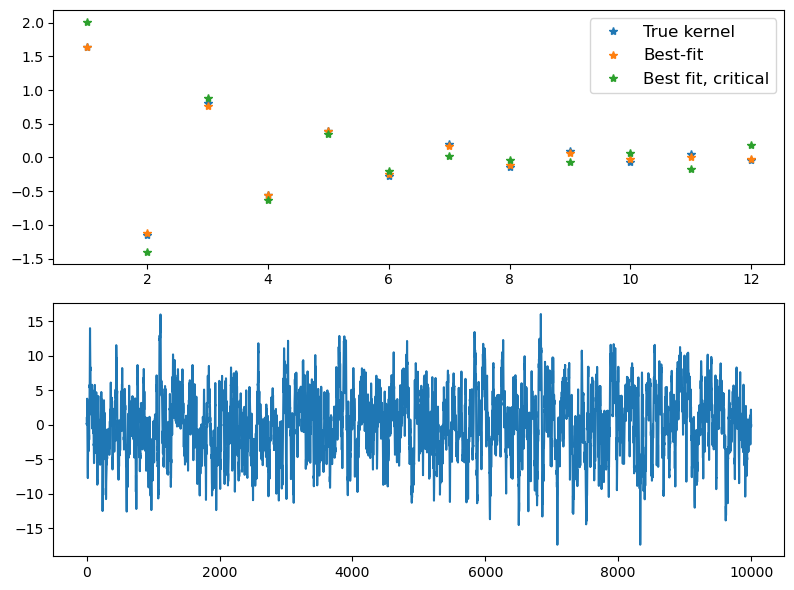

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6))
ax1.plot(np.arange(1, n + 1), kern, "*", label="True kernel")  # x-axis: lag 1..n (MATLAB plot index)
ax1.plot(np.arange(1, n + 1), kernf, "*", label="Best-fit")
ax1.plot(np.arange(1, n + 1), kernc, "*", label="Best fit, critical")
ax1.legend(fontsize=12)
ax2.plot(np.arange(1, T + 1), x)  # AR data
fig.tight_layout()
fig.savefig(FIGURES_DIR / "prox_crit_demo_crit_db.png", dpi=150, bbox_inches="tight")